# Figure 3a
Model cell population dynamics -/+ erlotinib on different stiffnesses

#### Load libraries
Should use ECM_model conda environment (see README)

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math
from pathlib import Path
import re
import sys

from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exists  
`SAVEDIR` = Path (outside of git repo) to save output files  
`DATADIR` = Path to data files 

In [28]:
SAVEFILES = True
OVERWRITE = True
SET_JPARAM = True

SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
if not os.path.exists(SAVEDIR) and SAVEFILES:
    os.mkdir(SAVEDIR)

    
DATADIR = Path("../../Data/cell_populations")

rcParams.update({'figure.autolayout': True})

# add path to fit functions
sys.path.insert(0, "./../../Python")
from fits import emg_fit_func

In [3]:
# include samples
if SET_JPARAM:
    filepaths = os.listdir(SAVEDIR)
    filenames = [f for f in filepaths if re.search('^cellcount_.*pso_2.csv$', f)]
    filepaths = [Path(SAVEDIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)
else:
    filepaths = os.listdir(DATADIR)
    filenames = [f for f in filepaths if re.search('^cell_counts.*orig.csv$', f)]
    filepaths = [Path(DATADIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)

[WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_0.6 kPa DMSO_0_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_0.6 kPa DMSO_1_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_0.6 kPa DMSO_2_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_0.6 kPa erlotinib_0_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_0.6 kPa erlotinib_1_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_0.6 kPa erlotinib_2_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_4 kPa DMSO_0_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_4 kPa DMSO_1_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_4 kPa DMSO_2_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_4 kPa erlotinib_0_param_pso_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/cellcount_4 kPa erlotinib_1_param_pso_2.csv'), WindowsPath('C:/Users/olesk

In [4]:
def calc_doub(filename):
    tmp = np.loadtxt(filename, delimiter=',')
    
    t = np.arange(0,121)
    new_r = []
    for num in t:
        vals = tmp[tmp[:,0]<=num]
        new_r.append([num, vals[-1,1]])
    
    doubs = []
    for num in t:
        doub = math.log(new_r[num][1]/new_r[0][1])/math.log(2)
        doubs.append([num, doub])
        
    return doubs
    

In [5]:
all_doubs = pd.DataFrame(columns=['Condition','Time','Doub'])
for filename in filepaths:
    doub = calc_doub(filename)
    tmp = [x[1] for x in doub]
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    t = np.arange(0,121)
    data = {
        'Condition': [name]*len(t), 
        'Time': t,
        'Doub': tmp}
    tmp_df = pd.DataFrame(data)
    
    all_doubs = pd.concat([all_doubs, tmp_df], ignore_index=True)
    


In [6]:
doub_arr = np.zeros((121,18))
n = 0
for filename in filepaths:
    
    split_n = str(filename).split('\\')
    name = split_n[-1].split('.c')[0]
    
    tmp = all_doubs.loc[all_doubs['Condition'] == name]
    doub_arr[:,n]=tmp['Doub']
    n+=1

    

In [7]:
means=[np.mean(doub_arr[:,0:2],axis=1), np.mean(doub_arr[:,3:5],axis=1), np.mean(doub_arr[:,6:8],axis=1), 
       np.mean(doub_arr[:,9:11],axis=1), np.mean(doub_arr[:,12:14],axis=1), np.mean(doub_arr[:,15:17],axis=1)]
    
stdevs=[np.std(doub_arr[:,0:2],axis=1), np.std(doub_arr[:,3:5],axis=1), np.std(doub_arr[:,6:8],axis=1), 
       np.std(doub_arr[:,9:11],axis=1), np.std(doub_arr[:,12:14],axis=1), np.std(doub_arr[:,15:17],axis=1)]


#### 

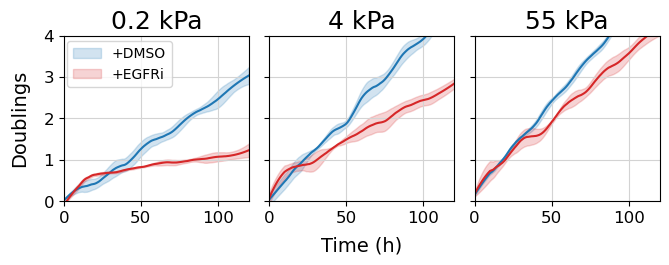

In [29]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = 0
ymax = 4

params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

t = np.arange(0,121)
axes[0].plot(t, savgol_filter(means[0],win,pol), color=c1)
axes[0].fill_between(t, savgol_filter(means[0] - stdevs[0],win,pol),
                     savgol_filter(means[0] + stdevs[0],win,pol), color=c1, alpha=0.2, label='+DMSO')
axes[0].plot(t, savgol_filter(means[1],win,pol), color=c2)
axes[0].fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c2, alpha=0.2, label='+EGFRi')
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('0.2 kPa')
axes[0].grid(color='lightgray')
axes[0].legend(loc=(0.02,0.69))

axes[1].plot(t, savgol_filter(means[2],win,pol), color=c1)
axes[1].fill_between(t, savgol_filter(means[2] - stdevs[2],win,pol), 
                     savgol_filter(means[2] + stdevs[2],win,pol), color=c1, alpha=0.2)
axes[1].plot(t, savgol_filter(means[3],win,pol), color=c2)
axes[1].fill_between(t, savgol_filter(means[3] - stdevs[3],win,pol), 
                     savgol_filter(means[3] + stdevs[3],win,pol), color=c2, alpha=0.2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].title.set_text('4 kPa')
axes[1].grid(color='lightgray')

axes[2].plot(t, savgol_filter(means[4],win,pol), color=c1)
axes[2].fill_between(t, savgol_filter(means[4] - stdevs[4],win,pol), 
                     savgol_filter(means[4] + stdevs[4],win,pol), color=c1, alpha=0.2)
axes[2].plot(t, savgol_filter(means[5],win,pol), color=c2)
axes[2].fill_between(t, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].title.set_text('55 kPa')
axes[2].grid(color='lightgray')


    
ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Doublings', labelpad=25)
fig.tight_layout(rect=(0, 0, 1, 1))

if SET_JPARAM:
    fig3a_fn = Path(SAVEDIR, 'fig3a_jparam.png')
else:
    fig3a_fn = Path(SAVEDIR, 'fig3a.png')

if SAVEFILES and (OVERWRITE or not fig3a_fn.exists()):
    plt.savefig(fig3a_fn, bbox_inches='tight')
else:
    plt.figure()

In [9]:
IMT_DATADIR = "../../Data/cell_cycle_timing"

In [14]:
if SET_JPARAM:
    filepaths = os.listdir(SAVEDIR)
    filenames = [f for f in filepaths if re.search('^IMTs.*PSO_2.csv$', f)]
    filepaths = [Path(SAVEDIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)
else:
    file_location = os.path.join(IMT_DATADIR,'*IMTs*.csv')
    filepaths = glob.glob(file_location)
    filepaths.sort()
    print(filepaths)

[WindowsPath('C:/Users/olesk/ECM_mod_output/IMTs_0.6 kPa DMSO_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/IMTs_0.6 kPa erlotinib_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/IMTs_4 kPa DMSO_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/IMTs_4 kPa erlotinib_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/IMTs_55 kPa DMSO_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/IMTs_55 kPa erlotinib_PSO_2.csv')]


In [15]:
IMTs = []
for f in filepaths:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

# all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)
centers = np.arange(0.5, 100.5, 1)  # histogram bin centers 


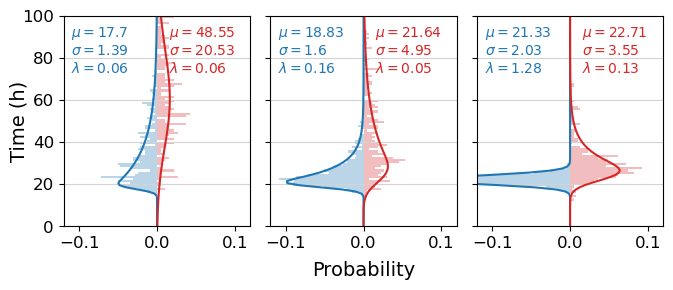

In [30]:
win = 21
pol = 2
size = (7.25,3.25)
c1 = "tab:blue"
c2 = "tab:red"
xmin = -0.12
xmax = 0.12
ymin = 0
ymax = 100

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

data = np.array(IMTs[0])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[0].plot(fitted_curve, centers, color=c1)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)


data = np.array(IMTs[1])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[0].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[0].plot(fitted_curve, centers, color=c2)
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].grid(color='lightgray', axis='y')
axes[0].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[2])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[1].plot(fitted_curve, centers, color=c1)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[3])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[1].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[1].plot(fitted_curve, centers, color=c2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].grid(color='lightgray', axis='y')
axes[1].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)

data = np.array(IMTs[4])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(-h, edges, orientation="horizontal", fill=True, color=c1, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
fitted_curve = [-x for x in fitted_curve]
axes[2].plot(fitted_curve, centers, color=c1)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(-0.11, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c1)

data = np.array(IMTs[5])
data = data[~np.isnan(data)]
h, edges =np.histogram(data, bins=range(0,101), density=True)
out = axes[2].stairs(h, edges, orientation="horizontal", fill=True, color=c2, alpha=0.3)
params = exponnorm.fit(data)
exp_c = 1/(params[0]*params[2])
popt = [exp_c, params[2], params[1]]
fitted_curve=list(emg_fit_func(centers,popt[0],popt[1],popt[2]))
axes[2].plot(fitted_curve, centers, color=c2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].grid(color='lightgray', axis='y')
axes[2].text(0.015, 73, f'$\mu = {round(popt[2],2)}$\n$\sigma = {round(popt[1],2)}$\n$\lambda = {round(popt[0],2)}$',
            color=c2)



ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel('Probability', labelpad=25)
ax.set_ylabel('Time (h)', labelpad=25)
#fig.tight_layout(rect=(0, 0, 1, 1))

if SET_JPARAM:
    fig3b_fn = Path(SAVEDIR, 'fig3b_jparam.png')
else:
    fig3b_fn = Path(SAVEDIR, 'fig3b.png')

if SAVEFILES and (OVERWRITE or not fig3b_fn.exists()):
    plt.savefig(fig3b_fn, bbox_inches='tight')
else:
    plt.figure()

In [17]:
init = [[0.05975, 1.95, 10.2, 0.073, 8.17, 28.12, 0.602]]
bounds1 = ((0.001, 0.01, 0.01, 0.01, 0.01, 5, 0.01),
              (10, 10, 20, 10, 10, 100, 1))
bounds2 = ((-5, 0), (0, 1), (0.5, 3), (-5, 0), (0, 1), (3, 4), (-5, -0.00001))

In [18]:
if SET_JPARAM:
    filepaths = os.listdir(SAVEDIR)
    filenames = [f for f in filepaths if re.search('^G1.*PSO_2.csv$', f)]
    filepaths = [Path(SAVEDIR, f) for f in filenames]
    filepaths.sort()
    print(filepaths)
else:
    file_location = os.path.join(IMT_DATADIR,'G1s*param_orig.csv')
    filepaths = glob.glob(file_location)
    filepaths.sort()
    print(filepaths)

[WindowsPath('C:/Users/olesk/ECM_mod_output/G1s_0.6 kPa DMSO_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/G1s_0.6 kPa erlotinib_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/G1s_4 kPa DMSO_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/G1s_4 kPa erlotinib_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/G1s_55 kPa DMSO_PSO_2.csv'), WindowsPath('C:/Users/olesk/ECM_mod_output/G1s_55 kPa erlotinib_PSO_2.csv')]


In [19]:
g1 = []
for f in filepaths:
    tmp_df = pd.read_csv(f,header=None).transpose()
#     tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    g1.append(tmp_df)
centers = np.arange(0.5, 100.5, 1)

In [20]:
from scipy.stats import exponnorm
import scipy.special as sse
from scipy.optimize import curve_fit
from scipy import stats
from sklearn.metrics import mean_squared_error
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
from scipy.special import rel_entr
from sklearn.neighbors import KernelDensity
import scipy.optimize as opt

In [21]:
def calculate_aic(LL, num_params):
    aic = 2*num_params - 2*LL
    return aic

def calculate_bic(LL, num_params, samp_size):
    bic = num_params*math.log(samp_size) - 2*LL
    return bic

from math import log10, floor
def round_sig(x, sig=2):
    return round(x, sig-int(floor(log10(abs(x))))-1)

def emg_fit_func_2(x, l, s, m, l_2, s_2, m_2, w):
    return w*(0.5*l*np.exp(0.5*l*(2*m+l*s*s-2*x))*sse.erfc((m+l*s*s-x)/(np.sqrt(2)*s))) + (1-w)*(0.5*l_2*np.exp(0.5*l_2*(2*m_2+l_2*s_2*s_2-2*x))*sse.erfc((m_2+l_2*s_2*s_2-x)/(np.sqrt(2)*s_2))) # exponential gaussian

def logl_emgv2(log_par, data):
    l,s,m = np.exp(log_par)
    eps = 10e-9
    return np.log(list(emg_fit_func(data, l, s, m)+eps)).sum()

# def logl_emg2v2(log_par, data):
#     l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
#     eps = 10e-12
#     return np.log(list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w)+eps)).sum()

def logl_emg2v2(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    eps = 10e-12
    temg2 = list(emg_fit_func_2(data, l , s, m, l_2, s_2, m_2, w))
    emg2 = [x + eps for x in temg2]
    ln_em2 = np.log(emg2)
    return ln_em2.sum()

def calc_aicc(AIC, num_params, samp_size):
    aicc = AIC + (2*num_params*(num_params+1)/(samp_size-num_params-1))
    return aicc

def calc_aicp(AICs):
    aicp = [math.exp((min(AICs)-AIC)/2) for AIC in AICs]
    return aicp


def emg_mle_v2(data, log_par, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emgv2(log_params, data),
    x0=np.array(log_par), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def emg2_mle_v2(data, log_par2, bnds):
    res = opt.minimize(
    fun=lambda log_params, data: -logl_emg2v2(log_params, data),
    x0=np.array(log_par2), args=(data,), bounds=bnds, method='L-BFGS-B')
    log_p = res.x
    params = [np.exp(y) for y in log_p]
    return log_p, params

def crit(log_par, data):
    data = np.array(data)
    l,s,m,l_2,s_2,m_2,w = np.exp(log_par)
    
    LL2 = logl_emg2v2(log_par, data)
    negLL2 = -LL2      
    return negLL2

def smooth(y, box_pts):
    box = np.ones(box_pts)/box_pts
    y_smooth = np.convolve(y, box, mode='same')
    return y_smooth


In [22]:
def fit_EMGMM(G1_times, initial=init[0], ax=None, loc=4, crit=crit):
#     G1_times = dat[(dat['Stiffness']==cond['stiff']) & (dat['Drug']==cond['drug'])]['G1_t']
#     G1_times = G1_times[~np.isnan(G1_times)]
    
#     G1_times = G1_times[~np.isnan(G1_times)]
    data = np.array(G1_times)
    data = data[~np.isnan(data)]
    
    init = [0.05975, 1.95, 10.2, 0.073, 8.17, 28.12, 0.602]
    bounds = ((0.001, 0.01, 0.01, 0.01, 0.01, 5, 0.01),
              (10, 10, 20, 10, 10, 100, 1))

    h, edges =np.histogram(data, bins=range(0,101), density=True)
    tmp = smooth(h,7)
    out = ax.stairs(h, edges, fill=True, color="tab:red", alpha=0.2)
    params = exponnorm.fit(data)
    LL = exponnorm.logpdf(data,*params).sum()
    AIC = calculate_aic(LL, 3)
    AICc = calc_aicc(AIC, 3, len(data))

    popt, pcov = opt.curve_fit(emg_fit_func_2, centers, tmp, p0=init, bounds=bounds, maxfev=50000)
    
    tmp = [math.log(x) for x in popt]
    bounds = ((-5, 0),
                 (0, 1),
                 (0.5, 3),
                 (-5, 0),
                 (0, 1),
                 (3, 4),
                 (-5, -0.00001))

    results = opt.minimize(crit, tmp, data, method = 'Nelder-Mead', bounds=bounds, options={'maxiter':10000})
    
    
    LL2 = logl_emg2v2(results.x, data)
    negLL2 = -LL2
    AIC2 = calculate_aic(LL2, 7)
    AICc2 = calc_aicc(AIC2, 7, len(data))

    AICs = [AICc, AICc2]
    AICp = calc_aicp(AICs)
    AICp_r = [round_sig(AICp[0], 3), round_sig(AICp[1], 3)]
    

    x = np.arange(0,100,0.1)
    y = emg_fit_func_2(x,*np.exp(results.x))       
    
    y1 = emg_fit_func(x, np.exp(results.x[0]), np.exp(results.x[1]), np.exp(results.x[2]))*np.exp(results.x[6])
    y2 = emg_fit_func(x, np.exp(results.x[3]), np.exp(results.x[4]), np.exp(results.x[5]))*(1-np.exp(results.x[6]))
    y3 = exponnorm.pdf(x, *params)
    ax.plot(x,y, color='black')
    ax.plot(x,y1, color='black', linestyle='dashed')
    ax.plot(x,y2, color='black', linestyle='dashed')
    ax.plot(x,y3, color='gray')
    h, edges =np.histogram(data, bins=range(0,101), density=True)
    ax.stairs(h, edges, fill=True, color="tab:red", alpha=0.2)

    LL2 = logl_emg2v2(results.x, G1_times)
    AIC2 = calculate_aic(LL2, 7)
    AICc2 = calc_aicc(AIC2, 7, len(G1_times))
    
    AICs = [AICc, AICc2]
    AICp = calc_aicp(AICs)
    AICp_r = [round_sig(AICp[0], 3), round_sig(AICp[1], 3)]
    
    # rc('text', usetex=True) #  # must have LaTeX installed
    # ax.text(loc, 0.11, r'$\underline{AICp}$', fontsize=12)
    
    # # if no LaTeX, use:
    rc('text', usetex=False) #  # must have LaTeX installed
    ax.text(loc, 0.11, r'${AICp}$', fontsize=12)
    ax.text(loc, 0.11, '_____', fontsize=12)
    
    rc('text', usetex=False)
    ax.text(loc, 0.097, f'EMG: {AICp_r[0]}', fontsize=12, color='gray')
    ax.text(loc, 0.087, f'EMG2: {AICp_r[1]}', fontsize=12)

    out = pd.Series(data={'LL':LL, 'AIC':AIC, 'AICc':AICc, 'params':params,
                         'LL2':LL2, 'AIC2':AIC2, 'AICc2':AICc2, 'params2':results.x, 'AICp':AICp_r})
          
    return(out)

C:\Users\olesk\AppData\Local\Temp\ipykernel_2504\2339956449.py:32: OptimizeWarning: Initial guess is not within the specified bounds
  results = opt.minimize(crit, tmp, data, method = 'Nelder-Mead', bounds=bounds, options={'maxiter':10000})


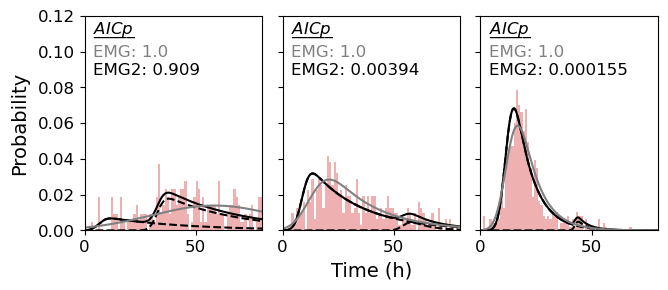

In [25]:
win = 21
pol = 2
size = (7.25,3.25)
ymin = 0
ymax = 0.12
xmin = 0
xmax = 80

# rc('text', usetex=True)
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'axes.edgecolor': "black",
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

fig, axes = plt.subplots(1, 3, figsize=size)

f0 = fit_EMGMM(g1[1], initial=init[0], ax=axes[0])
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
f1 = fit_EMGMM(g1[3], initial=init[0], ax=axes[1])
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
f2 = fit_EMGMM(g1[5], initial=init[0], ax=axes[2])
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])

ax1 = fig.add_subplot(111, frameon=False)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlabel('Time (h)', labelpad=22)
ax1.set_ylabel('Probability', labelpad=40)
fig.tight_layout(rect=(0, 0, 1, 1))

if SET_JPARAM:
    fig3c_fn = Path(SAVEDIR, 'fig3c_jparam.png')
else:
    fig3c_fn = Path(SAVEDIR, 'fig1c.png')

if SAVEFILES and (OVERWRITE or not fig3c_fn.exists()):
    plt.savefig(fig3c_fn, bbox_inches='tight')
else:
    plt.figure()

In [20]:
f0

LL                                              -1254.868872
AIC                                              2515.737743
AICc                                              2515.82285
params     (3.1822114402812733, 12.089317834369979, 7.142...
LL2                                             -1258.393453
AIC2                                             2530.786905
AICc2                                            2514.786905
params2    [-3.206091693308448, 0.9999997997634011, 1.765...
AICp                                            [0.596, 1.0]
dtype: object